# Crack Depth Explorer: demo

Measures cracks in 3D from four photos lit from four sides (photometric stereo). The demo scene is rendered by `render.py`, so the true surface is known and every number can be checked.

In [1]:
%matplotlib inline
import json
import matplotlib.pyplot as plt
import numpy as np

from analyze import run
from render import make_scene, render
from report import plot_report

!python render.py --seed 7 --out demo
FILES = [f'demo/scene_{n}.png' for n in 'NESW']

Wrote 4 images, truth.npz and lights.json to demo/


## 1. The four photos
The camera does not move; the light comes from the top, right, bottom and left. Each crack wall is bright when it faces the light and dark when it faces away.

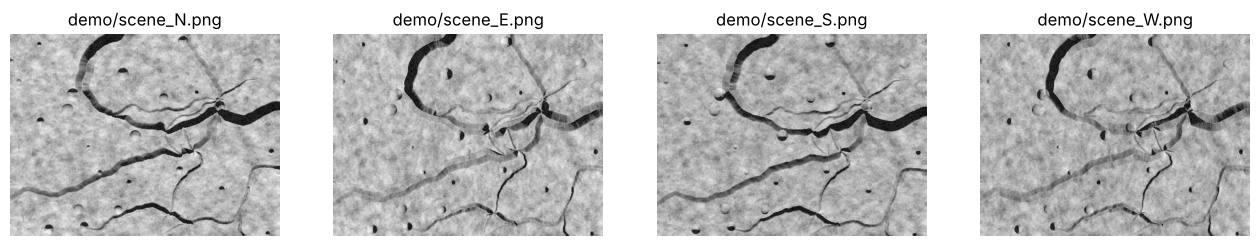

In [2]:
import cv2
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
for a, f in zip(ax, FILES):
    a.imshow(cv2.imread(f, 0), cmap='gray'); a.set_title(f); a.axis('off')
plt.show()

## 2. Surface normals → height map → cracks

{
  "crack_segments": 33,
  "total_length_mm": 283.4,
  "max_depth_mm": 2.86,
  "median_depth_mm": 1.01,
  "max_width_mm": 2.24,
  "median_width_mm": 0.8,
  "crack_area_%": 16.3
}


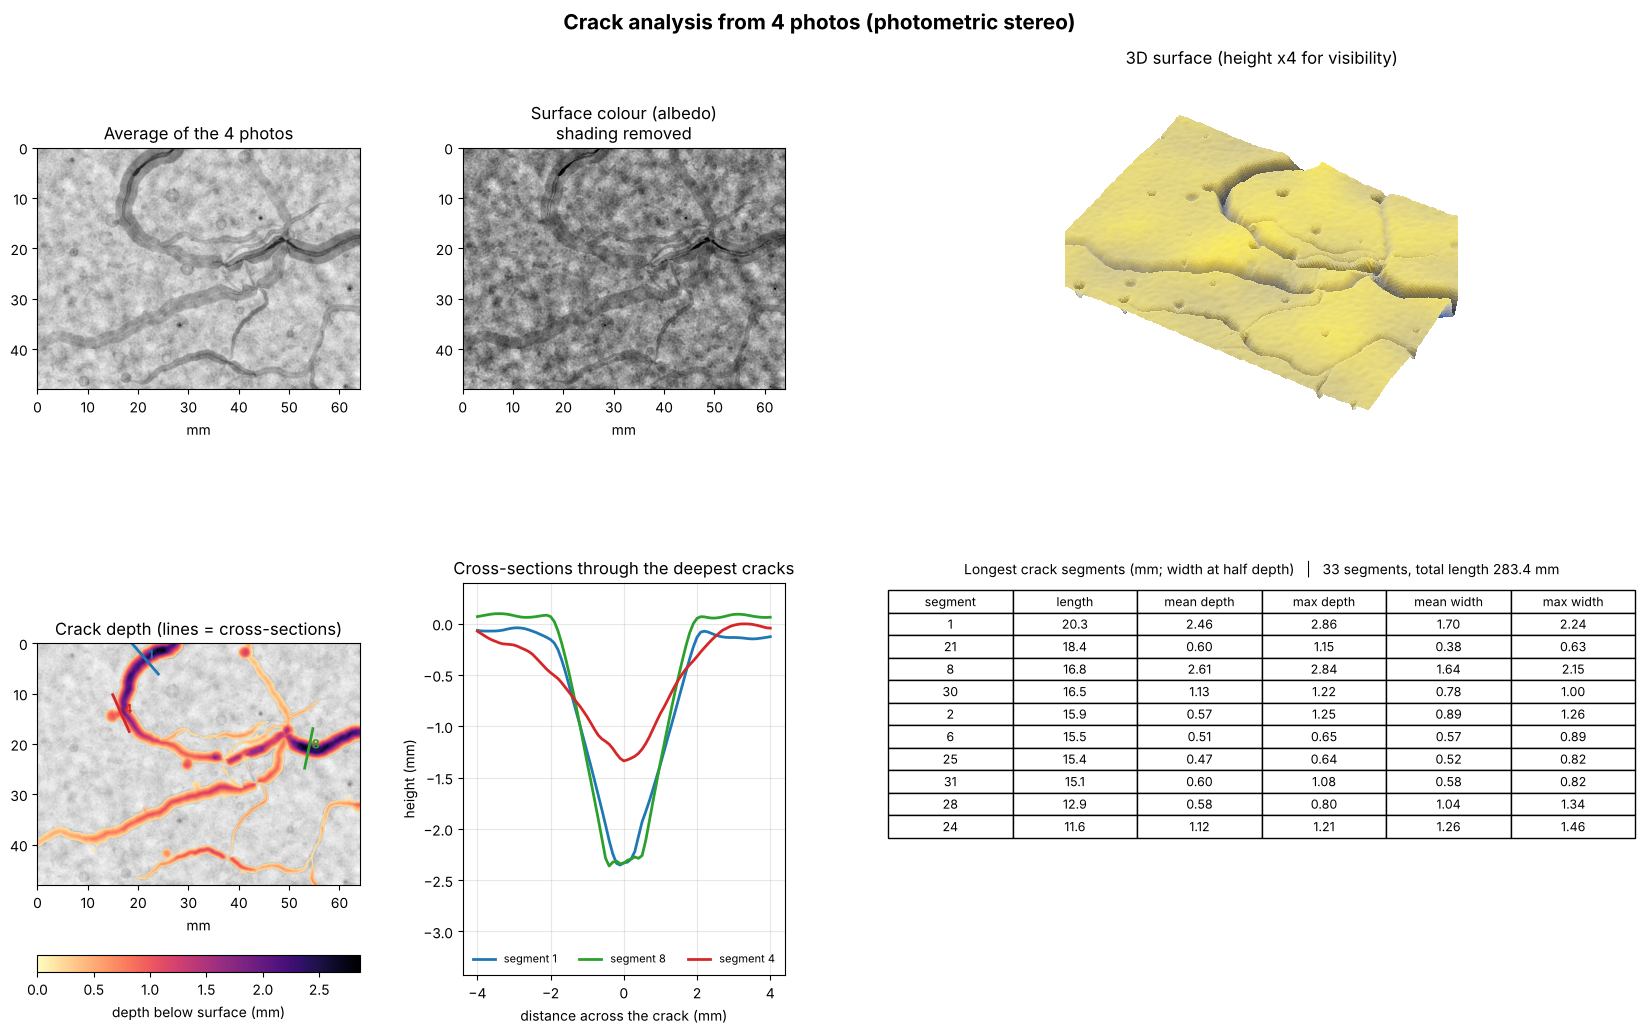

In [3]:
res, imgs, albedo = run(FILES, azimuth=(90, 0, 270, 180), elevation=45, px_mm=0.1)
print(json.dumps(res.summary(), indent=2))
plot_report(res, imgs.mean(0) ** (1 / 2.2), albedo)
plt.show()

## 3. How close is it to the truth?

height error: median 0.046 mm overall


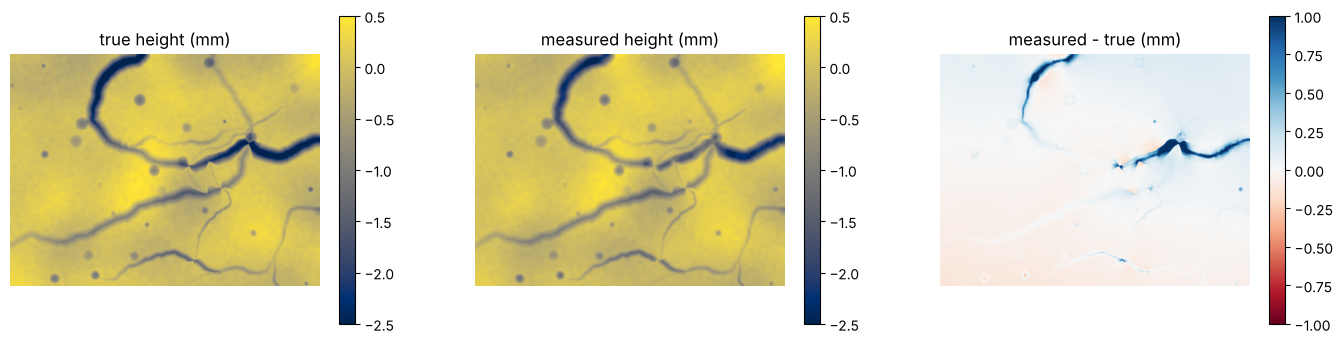

In [4]:
truth = np.load('demo/truth.npz')
zt = truth['height'] - np.median(truth['height'])
err = res.height - zt
crack = truth['crack_depth'] > 0
print(f'height error: median {np.median(np.abs(err)):.3f} mm overall')
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, z, t in zip(ax, [zt, res.height], ['true height (mm)', 'measured height (mm)']):
    im = a.imshow(z, cmap='cividis', vmin=-2.5, vmax=0.5); a.set_title(t); a.axis('off'); plt.colorbar(im, ax=a)
im = ax[2].imshow(err, cmap='RdBu', vmin=-1, vmax=1); ax[2].set_title('measured - true (mm)'); ax[2].axis('off')
plt.colorbar(im, ax=ax[2]); plt.show()

The largest errors are at the bottom of the deepest, narrowest cracks: there the floor is in shadow in most photos, so the measured depth is a lower bound. `validate.py` measures this on 20 unseen scenes.

In [5]:
print(json.dumps(json.load(open('results/validation.json'))['accuracy'], indent=2))

{
  "scenes": 20,
  "centre_line_points": 41299,
  "true_depth_range_mm": [
    0.3,
    4.02
  ],
  "photometric_stereo": {
    "depth_mae_mm": 0.208,
    "depth_median_abs_error_mm": 0.098,
    "depth_bias_mm": -0.159,
    "depth_relative_error_median_%": 12.8,
    "depth_correlation": 0.929,
    "width_mae_mm": 0.209,
    "width_median_abs_error_mm": 0.143,
    "detection_precision": 0.955,
    "detection_recall": 0.966
  },
  "single_image_shading_best_case": {
    "depth_mae_mm": 0.553,
    "depth_median_abs_error_mm": 0.46,
    "depth_correlation": 0.314,
    "fitted_scale_mm_per_index": 1.52
  }
}


## 4. Interactive profile tool
Run in Jupyter with `ipympl` (`pip install ipympl`), or from a terminal:

`python profile_tool.py demo/scene_N.png demo/scene_E.png demo/scene_S.png demo/scene_W.png --px-mm 0.1`

In [6]:
# %matplotlib widget
# from profile_tool import ProfileTool
# ProfileTool(res, imgs.mean(0) ** (1 / 2.2)).show()